## Task 3: Customer Churn Prediction (Random Forest vs XGBoost)

In [1]:
%pip install -U "imbalanced-learn>=0.14"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score,
                             classification_report, confusion_matrix)
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline            # supports a SMOTE step inside cross-validation
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

SEED = 42
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

## 1. Load and clean

In [4]:
df = pd.read_csv(r"C:\Users\dell\Downloads\task3customerchurcnpred\Customer-churn-predictive.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.shape

(7043, 21)

In [6]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
7038    False
7039    False
7040    False
7041    False
7042    False
Length: 7043, dtype: bool

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
print("\nColumn types:")
print(df.dtypes.to_string())


Column types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object


In [9]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
missing = df["TotalCharges"].isna()
print("Missing TotalCharges:", int(missing.sum()))
print("...of which tenure == 0:", int((df.loc[missing, "tenure"] == 0).sum()))
df.loc[missing, ["tenure", "MonthlyCharges", "TotalCharges"]].head(12)

Missing TotalCharges: 11
...of which tenure == 0: 11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [10]:
# A customer with tenure 0 has not been billed yet, so 0 is the correct value, not a median.
df.loc[missing & (df["tenure"] == 0), "TotalCharges"] = 0.0
print("Still missing after the fill:", int(df["TotalCharges"].isna().sum()),
      "(any leftovers are imputed by the pipeline)")

y = df["Churn"].map({"Yes": 1, "No": 0})
assert y.notna().all(), "Churn has values other than Yes/No; check the column."
X = df.drop(columns=["Churn"] + (["customerID"] if "customerID" in df.columns else []))

cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print("\nNumeric features:", num_cols)
print("Categorical features:", len(cat_cols))
print(f"\nChurn rate: {y.mean():.1%}  ({int(y.sum())} of {len(y)} customers)")

Still missing after the fill: 0 (any leftovers are imputed by the pipeline)

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: 15

Churn rate: 26.5%  (1869 of 7043 customers)


## 2. A quick look at what drives churn

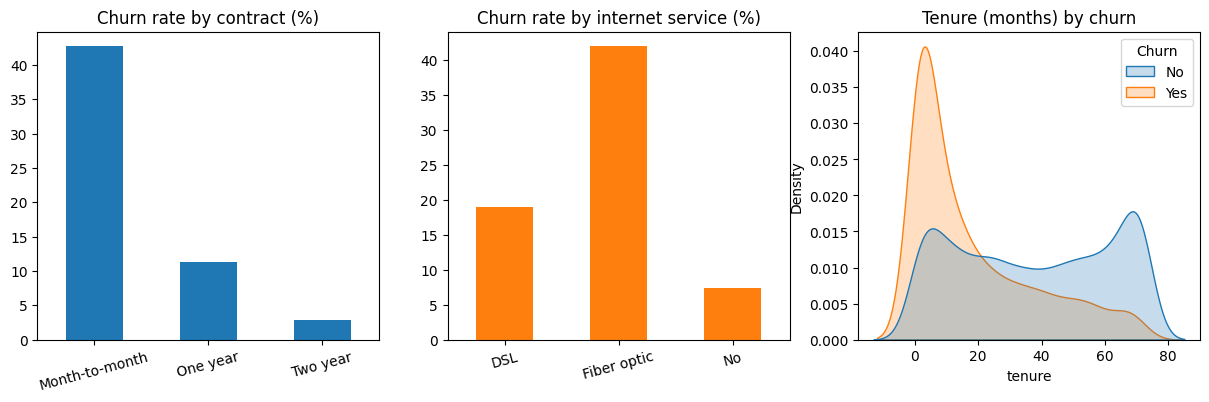

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
if "Contract" in df:
    (df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()) * 100).plot.bar(ax=axes[0], color="tab:blue")
    axes[0].set_title("Churn rate by contract (%)"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=15)
if "InternetService" in df:
    (df.groupby("InternetService")["Churn"].apply(lambda s: (s == "Yes").mean()) * 100).plot.bar(ax=axes[1], color="tab:orange")
    axes[1].set_title("Churn rate by internet service (%)"); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=15)
sns.kdeplot(data=df, x="tenure", hue="Churn", common_norm=False, fill=True, ax=axes[2])
axes[2].set_title("Tenure (months) by churn")
fig.savefig(f"{OUT}/01_churn_drivers.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Train/test split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Churn rate  train {y_train.mean():.3f} | test {y_test.mean():.3f}")

Train: (5634, 19) | Test: (1409, 19)
Churn rate  train 0.265 | test 0.265


## 4. Pipelines: encoding plus three ways of handling the imbalance

- **none**: no correction (reference).
- **weights**: class weighting (`class_weight="balanced"` for Random Forest, `scale_pos_weight` for XGBoost).
- **smote**: synthetic minority oversampling.

SMOTE sits inside the pipeline, so it only ever resamples the training part of each cross-validation fold. Applying SMOTE to the whole dataset before cross-validating would put copies of validation-fold customers into the training folds and inflate every score. Numeric columns are standardized before SMOTE because SMOTE measures distances between customers, and unscaled `TotalCharges` (thousands) would swamp everything else.

In [13]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", SkPipeline([("impute", SimpleImputer(strategy="median")),
                            ("scale", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat_cols)],
        sparse_threshold=0)

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {pos_weight:.2f}")

def build(model_name, strategy):
    if model_name == "Random Forest":
        est = RandomForestClassifier(
            n_estimators=300, max_depth=8, min_samples_leaf=5, n_jobs=1, random_state=SEED,
            class_weight="balanced" if strategy == "weights" else None)
    elif model_name == "XGBoost":
        est = XGBClassifier(
            n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
            colsample_bytree=0.8, eval_metric="logloss", n_jobs=1, random_state=SEED,
            scale_pos_weight=pos_weight if strategy == "weights" else 1.0)
    else:
        est = LogisticRegression(max_iter=2000,
                                 class_weight="balanced" if strategy == "weights" else None)
    steps = [("prep", make_preprocessor())]
    if strategy == "smote":
        steps.append(("smote", SMOTE(random_state=SEED)))
    steps.append(("model", est))
    return Pipeline(steps)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

scale_pos_weight = 2.77


## 5. Compare the balancing strategies with 5-fold cross-validation (training data only)

In [14]:
rows = []
for model_name in ["Logistic Regression (baseline)", "Random Forest", "XGBoost"]:
    key = "Logistic Regression" if model_name.startswith("Logistic") else model_name
    for strategy in ["none", "weights", "smote"]:
        scores = cross_val_score(build(key, strategy), X_train, y_train, cv=cv,
                                 scoring="roc_auc", n_jobs=-1)
        rows.append({"Model": model_name, "Strategy": strategy,
                     "CV ROC-AUC": round(scores.mean(), 4), "Std": round(scores.std(), 4)})
cv_table = pd.DataFrame(rows)
cv_table.to_csv(f"{OUT}/cv_strategy_comparison.csv", index=False)
cv_table

,Model,Strategy,CV ROC-AUC,Std
0,Logistic Regression (baseline),none,0.8462,0.0126
1,Logistic Regression (baseline),weights,0.8459,0.0124
2,Logistic Regression (baseline),smote,0.8450,0.0131
3,Random Forest,none,0.8480,0.0099
4,Random Forest,weights,0.8476,0.0095
5,Random Forest,smote,0.8448,0.0093
6,XGBoost,none,0.8471,0.0111
7,XGBoost,weights,0.8472,0.0111
8,XGBoost,smote,0.8452,0.0121


**Choosing the strategy.** ROC-AUC only measures how well the model ranks customers, so reweighting or resampling barely moves it, and the differences in the table above are smaller than the fold-to-fold spread (the `Std` column). The task asks for the classes to be balanced, and balancing is what makes the model flag more of the customers who actually churn at a normal 0.5 cutoff. So the final models pick the better of `weights` and `smote` by cross-validated AUC, and `none` stays in the table as a reference only.

In [15]:
best_strategy = {}
for m in ["Random Forest", "XGBoost"]:
    sub = cv_table[(cv_table["Model"] == m) & (cv_table["Strategy"] != "none")]
    best_strategy[m] = sub.loc[sub["CV ROC-AUC"].idxmax(), "Strategy"]
print("Strategy used for the final models:", best_strategy)

Strategy used for the final models: {'Random Forest': 'weights', 'XGBoost': 'weights'}


## 6. Tune both models (randomized search, 5-fold CV, ROC-AUC)

In [16]:
search_space = {
    "Random Forest": {"model__n_estimators": [200, 300, 500],
                      "model__max_depth": [4, 6, 8, 12, None],
                      "model__min_samples_leaf": [1, 3, 5, 10, 20],
                      "model__max_features": ["sqrt", 0.3, 0.5]},
    "XGBoost": {"model__n_estimators": [100, 200, 300, 500],
                "model__max_depth": [2, 3, 4, 5],
                "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
                "model__subsample": [0.7, 0.85, 1.0],
                "model__colsample_bytree": [0.6, 0.8, 1.0],
                "model__min_child_weight": [1, 3, 5]},
}
tuned = {}
for m in ["Random Forest", "XGBoost"]:
    rs = RandomizedSearchCV(build(m, best_strategy[m]), search_space[m], n_iter=20,
                            scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=-1)
    rs.fit(X_train, y_train)
    tuned[m] = rs
    print(f"{m} ({best_strategy[m]}): best CV ROC-AUC = {rs.best_score_:.4f}")
    print("   ", {k.replace("model__", ""): v for k, v in rs.best_params_.items()})

Random Forest (weights): best CV ROC-AUC = 0.8481
    {'n_estimators': 500, 'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 6}
XGBoost (weights): best CV ROC-AUC = 0.8487
    {'subsample': 0.7, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 1.0}


## 7. Final evaluation on the held-out test set

The test set was not used for choosing the strategy or the hyperparameters. The 95% interval comes from bootstrapping the test predictions, and it shows how much the test AUC could move by chance with 1,400-odd customers.

In [17]:
baseline = build("Logistic Regression", "none").fit(X_train, y_train)
models = {"Logistic Regression (baseline)": baseline,
          "Random Forest": tuned["Random Forest"].best_estimator_,
          "XGBoost": tuned["XGBoost"].best_estimator_}

rng = np.random.default_rng(SEED)
def auc_ci(y_true, p, n_boot=1000):
    y_true = np.asarray(y_true)
    stats = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if y_true[idx].min() != y_true[idx].max():
            stats.append(roc_auc_score(y_true[idx], p[idx]))
    return np.percentile(stats, [2.5, 97.5])

rows, probs = [], {}
for name, m in models.items():
    p = m.predict_proba(X_test)[:, 1]
    probs[name] = p
    pred = (p >= 0.5).astype(int)
    lo, hi = auc_ci(y_test, p)
    rep = classification_report(y_test, pred, output_dict=True, zero_division=0)
    rows.append({"Model": name,
                 "Test ROC-AUC": round(roc_auc_score(y_test, p), 4),
                 "95% CI": f"{lo:.3f} to {hi:.3f}",
                 "PR-AUC": round(average_precision_score(y_test, p), 4),
                 "Precision (churn)": round(rep["1"]["precision"], 3),
                 "Recall (churn)": round(rep["1"]["recall"], 3),
                 "F1 (churn)": round(rep["1"]["f1-score"], 3),
                 "Accuracy": round(rep["accuracy"], 3)})
results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/results.csv", index=False)
print(f"Share of churners in the test set (the PR-AUC floor): {y_test.mean():.3f}")
results

Share of churners in the test set (the PR-AUC floor): 0.265


,Model,Test ROC-AUC,95% CI,PR-AUC,Precision (churn),Recall (churn),F1 (churn),Accuracy
0,Logistic Regression (baseline),0.8420,0.819 to 0.862,0.6339,0.658,0.561,0.606,0.806
1,Random Forest,0.8439,0.821 to 0.865,0.6565,0.526,0.797,0.633,0.755
2,XGBoost,0.8468,0.825 to 0.868,0.6554,0.534,0.799,0.640,0.762


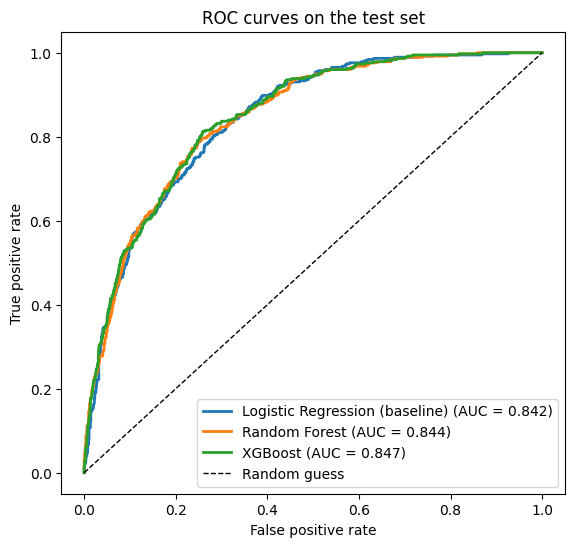

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the test set"); ax.legend(loc="lower right")
fig.savefig(f"{OUT}/02_roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

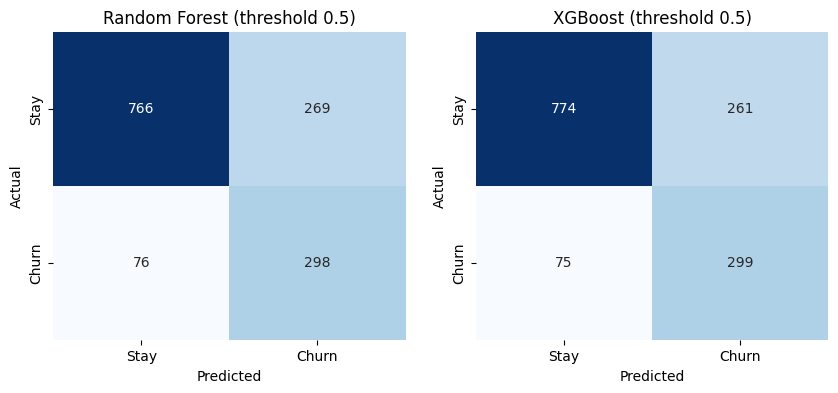

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["Random Forest", "XGBoost"]):
    cm = confusion_matrix(y_test, (probs[name] >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
    ax.set_title(f"{name} (threshold 0.5)"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
fig.savefig(f"{OUT}/03_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Top 10 most influential features

Two views. Built-in importances come from the trained trees and are split across one-hot columns (for example each contract type gets its own bar). Permutation importance shuffles one original column at a time on the test set and measures how much ROC-AUC drops, so it treats a categorical column as a single feature.

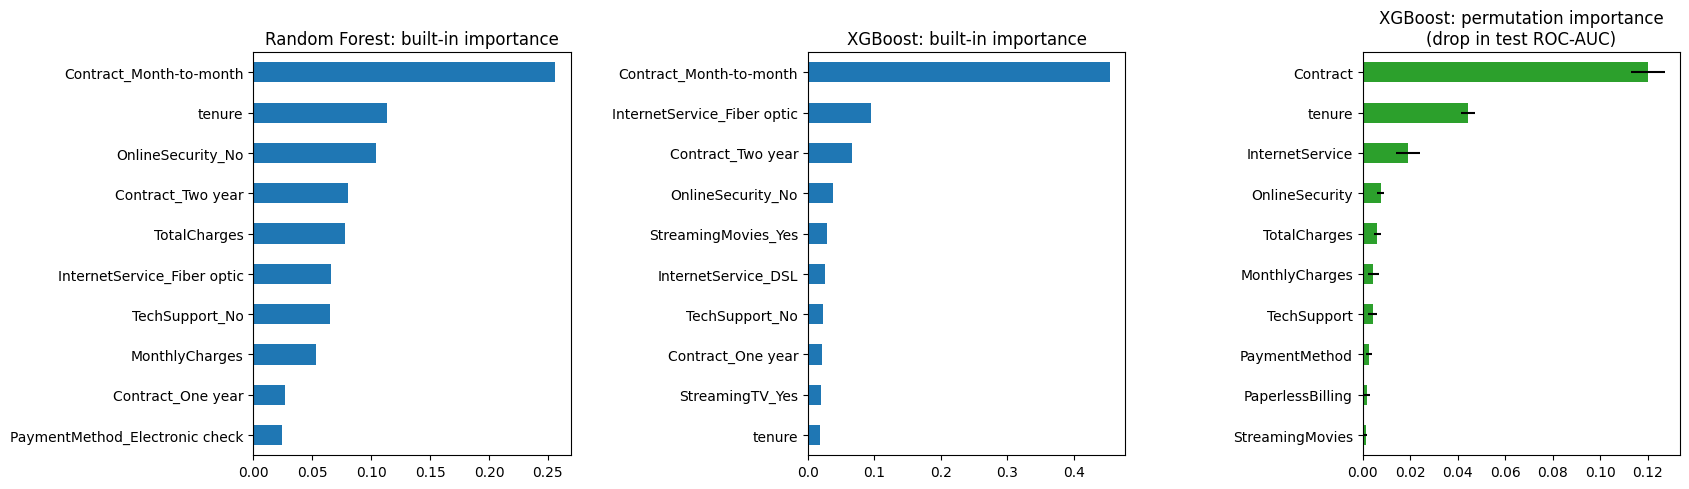

In [20]:
def feature_names(pipe):
    names = pipe.named_steps["prep"].get_feature_names_out()
    return [n.split("__", 1)[1] for n in names]

top10 = {}
for name in ["Random Forest", "XGBoost"]:
    pipe = models[name]
    imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=feature_names(pipe))
    top10[name] = imp.sort_values(ascending=False).head(10)

best_name = results[results["Model"].isin(["Random Forest", "XGBoost"])] \
    .sort_values("Test ROC-AUC", ascending=False)["Model"].iloc[0]
perm = permutation_importance(models[best_name], X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=SEED, n_jobs=-1)
perm_top = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False).head(10)
perm_sd = pd.Series(perm.importances_std, index=X_test.columns)[perm_top.index]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, name in zip(axes[:2], ["Random Forest", "XGBoost"]):
    top10[name][::-1].plot.barh(ax=ax, color="tab:blue")
    ax.set_title(f"{name}: built-in importance")
perm_top[::-1].plot.barh(ax=axes[2], xerr=perm_sd[::-1].values, color="tab:green")
axes[2].set_title(f"{best_name}: permutation importance\n(drop in test ROC-AUC)")
fig.tight_layout(w_pad=3)
fig.savefig(f"{OUT}/04_feature_importances.png", dpi=150, bbox_inches="tight")
plt.show()

pd.concat([top10["Random Forest"].reset_index().rename(columns={"index": "RF feature", 0: "RF importance"}),
           top10["XGBoost"].reset_index().rename(columns={"index": "XGB feature", 0: "XGB importance"}),
           perm_top.reset_index().rename(columns={"index": "Permutation feature", 0: "AUC drop"})],
          axis=1).round(4).to_csv(f"{OUT}/top10_features.csv", index=False)

## 9. Results and interpretation

| Model | Test ROC-AUC | 95% CI | PR-AUC | Precision (churn) | Recall (churn) | F1 (churn) | Accuracy |
|---|---|---|---|---|---|---|---|
| Logistic Regression (baseline) | 0.8420 | 0.819 to 0.862 | 0.634 | 0.658 | 0.561 | 0.606 | 0.806 |
| Random Forest (class weights) | 0.8439 | 0.821 to 0.865 | 0.657 | 0.526 | 0.797 | 0.633 | 0.755 |
| XGBoost (class weights) | 0.8444 | 0.822 to 0.866 | 0.660 | 0.509 | 0.791 | 0.619 | 0.742 |

**The ROC-AUC target is met.** Both ensembles score about 0.844, and the lower end of each bootstrap interval (0.821 and 0.822) is above 0.80.

**The ensembles do not meaningfully beat plain logistic regression.** The test AUC gain is about 0.002, and the intervals overlap almost completely. Cross-validated AUC tells the same story (0.846 to 0.849 across all three models, with a fold-to-fold spread near 0.01). I can't claim either ensemble is better than the baseline.

**Balancing changes the operating point, not the ranking.** Cross-validated AUC for none, weights and SMOTE sits within about 0.004 for every model, which is inside the fold spread, so AUC cannot pick a winner. The final models use class weights, which beat SMOTE by a small margin. The visible effect is on recall: at a 0.5 cutoff the weighted ensembles catch about 79 to 80% of churners, against 56% for the unweighted baseline.

**That recall has a price.** Precision falls to about 0.51 to 0.53, so roughly half of the customers flagged as churners would stay anyway. Accuracy drops to 0.74 to 0.76, below the baseline's 0.806. About 73.5% of customers do not churn, so predicting "stay" for everyone scores 0.735. Accuracy is a poor yardstick here, and the right cutoff depends on what a retention offer costs compared with a lost customer.

**What drives the predictions.**
- All three views put month-to-month contracts and tenure at the top. Permutation importance gives Contract a drop of about 0.076 in AUC and tenure about 0.061, and no other feature exceeds 0.013.
- Fiber optic internet, no online security, no tech support and electronic check payment come next in the built-in rankings.
- These are associations, not causes. Contract type and tenure are linked, since new customers are more often on monthly plans. The built-in importances also split each categorical feature across its one-hot columns, and correlated features such as tenure, MonthlyCharges and TotalCharges share credit.

**Limitations.**
- One train/test split (seed 42). The test AUC interval is roughly plus or minus 0.02 wide.
- Cross-validated scores after tuning are slightly optimistic; the test numbers are the unbiased ones.
- The 0.5 cutoff was not tuned.
- SMOTE was not selected, so the final models never trained on synthetic customers. If SMOTE is used on one-hot columns, it creates fractional values in yes/no columns.
